# Phase 2: Feature Engineering

The models can't learn from a raw list of readings. They need each row to say "here's what the VM looked like recently, now guess its CPU at the next reading". This notebook builds those rows and then splits them into training and test data by time.

**What goes in:** `data/processed/cleaned_vms.parquet` from Phase 1.

**What comes out (all in `data/processed/`):**
- `features_main.parquet`: every feature row for the 50 main-group VMs, with a `split` column saying train or test
- `train.parquet` / `test.parquet`: the same rows, already separated, for the tree models
- `features_generalization.parquet`: feature rows for the 100 hold-out VMs (used only in Phase 9)
- `feature_columns.json`: the exact list of model inputs, so every later notebook uses the same columns in the same order

Plus tables in `results/tables/phase2_*`, one chart in `results/charts/`, and the log `results/logs/phase02_feature_engineering.log`.

**Sample size** (agreed after the Phase 1b timing check): 50 VMs in the main group, 100 VMs in the generalization group.

**Run time:** about 1–2 minutes. Use `Runtime → Run all`.

## 0. Setup

In [ ]:
# Mount Google Drive (Colab) or use the local Drive folder (PC), then load our shared code.
import os, sys, importlib

try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_ROOT = '/content/drive/MyDrive/Green_ML_Project'
except ImportError:
    PROJECT_ROOT = r'H:\My Drive\Green_ML_Project'   # running on the PC instead of Colab

os.environ['GREEN_ML_ROOT'] = PROJECT_ROOT
sys.path.insert(0, os.path.join(PROJECT_ROOT, 'scripts'))

import config as C
import utils as U
importlib.reload(C); importlib.reload(U)   # picks up any edits to the scripts without restarting

print('Project folder:', C.PROJECT_ROOT)
print('Folder found:  ', os.path.isdir(C.PROJECT_ROOT))

Mounted at /content/drive
Project folder: /content/drive/MyDrive/Green_ML_Project
Folder found:   True


In [ ]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 40)

log = U.get_logger('phase02_feature_engineering')
log.info(f'Sample size: {C.N_TRAIN_VMS} main-group VMs, {C.N_GEN_VMS} generalization VMs')

RUN STARTED 2026-10-03 20:28:44 | phase02_feature_engineering
python 3.13.15 | pandas 2.2.3 | numpy 2.1.3 | machine: Linux-6.6.122+-x86_64-with-glibc2.39
project root: /content/drive/MyDrive/Green_ML_Project
Sample size: 50 main-group VMs, 100 generalization VMs


## 1. Load the cleaned data and pick the sample

Phase 1 cleaned 100 VMs per group and numbered them with `pool_rank` in shuffled order. Here we keep `pool_rank < 50` from the main group and `pool_rank < 100` from the generalization group.

In [ ]:
clean = pd.read_parquet(C.DATA_PROCESSED / 'cleaned_vms.parquet')
main = clean[(clean['pool'] == 'main') & (clean['pool_rank'] < C.N_TRAIN_VMS)]
gen = clean[(clean['pool'] == 'generalization') & (clean['pool_rank'] < C.N_GEN_VMS)]

assert main['vm_id'].nunique() == C.N_TRAIN_VMS, 'not enough main-group VMs - check Phase 1'
assert gen['vm_id'].nunique() == C.N_GEN_VMS, 'not enough generalization VMs - check Phase 1'
assert not set(main['vm_id']) & set(gen['vm_id']), 'the two groups overlap!'

log.info(f'Main group: {main["vm_id"].nunique()} VMs, {len(main):,} readings')
log.info(f'Generalization group: {gen["vm_id"].nunique()} VMs, {len(gen):,} readings')

Main group: 50 VMs, 401,718 readings
Generalization group: 100 VMs, 817,478 readings


## 2. Building the features

Picture standing at reading **t** for one VM. We're allowed to look at that reading and anything before it, but nothing after. The task is to predict CPU% at the **next** reading, **t+1**, which is 5 minutes ahead.

| Feature | What it is | Why it helps |
|---|---|---|
| `cpu_usage_pct`, `mem_usage_pct` | CPU% and memory% right now (at t) | the best single clue to the next value |
| `cpu_lag_1..3`, `mem_lag_1..3` | the same values 1, 2 and 3 readings ago (5, 10 and 15 minutes back) | shows whether load is rising or falling |
| `cpu_roll_mean_6`, `cpu_roll_std_6` | average and spread of CPU% over the last 6 readings (t-5 … t, half an hour) | smooths out noise; the spread shows how jumpy the VM is |
| `cpu_cores` | number of virtual CPU cores | bigger VMs behave differently |
| disk and network columns | I/O activity right now | busy I/O often comes with CPU spikes |
| `hour`, `minute` | time of day of reading t | many workloads follow a daily pattern |
| **`target_cpu_next`** | **CPU% at t+1, the value we predict** | |

**Memory as a percentage:** we use `mem_usage_pct` = memory used ÷ memory provisioned × 100, not raw kilobytes. A 2 GB VM and a 64 GB VM can then be compared on the same scale.

**Avoiding leakage:** leakage means a model quietly gets to see the answer during training, so its scores look better than they would in real use. We guard against it in three ways:
1. Every feature is computed **separately for each VM** (`groupby('vm_id')`), so one VM's numbers never leak into another's.
2. Lags and the rolling window only look **backwards** from t. The rolling window covers t-5 … t, and the target is t+1, so the target is never inside the window.
3. The first 5 readings of each VM (not enough history for the window yet) and the last reading (there's no "next" value to predict) are dropped.

The code lives in `scripts/utils.py` (`build_features`). That way Phase 9 builds generalization features with exactly the same function.

In [ ]:
with U.Timer() as t:
    feat_main = U.build_features(main)
    feat_gen = U.build_features(gen)
log.info(f'Features built in {t.seconds:.1f} s')
log.info(f'Main group: {len(main):,} readings -> {len(feat_main):,} feature rows '
         f'({len(main) - len(feat_main):,} dropped: first 5 + last 1 per VM)')
log.info(f'Generalization group: {len(gen):,} readings -> {len(feat_gen):,} feature rows')
log.info(f'Model inputs ({len(U.FEATURE_COLUMNS)}): {U.FEATURE_COLUMNS}')

feat_main[['vm_id', 'timestamp'] + U.FEATURE_COLUMNS + [C.TARGET]].head(8)

Features built in 1.7 s
Main group: 401,718 readings -> 401,418 feature rows (300 dropped: first 5 + last 1 per VM)
Generalization group: 817,478 readings -> 816,878 feature rows
Model inputs (17): ['cpu_usage_pct', 'mem_usage_pct', 'cpu_cores', 'cpu_lag_1', 'cpu_lag_2', 'cpu_lag_3', 'mem_lag_1', 'mem_lag_2', 'mem_lag_3', 'cpu_roll_mean_6', 'cpu_roll_std_6', 'disk_read_kbps', 'disk_write_kbps', 'net_received_kbps', 'net_transmitted_kbps', 'hour', 'minute']


,vm_id,timestamp,cpu_usage_pct,mem_usage_pct,cpu_cores,cpu_lag_1,cpu_lag_2,cpu_lag_3,mem_lag_1,mem_lag_2,mem_lag_3,cpu_roll_mean_6,cpu_roll_std_6,disk_read_kbps,disk_write_kbps,net_received_kbps,net_transmitted_kbps,hour,minute,target_cpu_next
0,21,2013-08-12 14:05:46,0.000000,1.333313,2,0.566667,0.500000,0.400000,1.866659,1.533324,1.933330,0.244444,0.272981,0.000000,0.666667,0.0,0.000000,14,5,0.733333
1,21,2013-08-12 14:10:46,0.733333,2.199980,2,0.000000,0.566667,0.500000,1.333313,1.866659,1.533324,0.366667,0.304047,0.000000,0.666667,2.4,5.666667,14,10,0.000000
2,21,2013-08-12 14:15:46,0.000000,1.399981,2,0.733333,0.000000,0.566667,2.199980,1.333313,1.866659,0.366667,0.304047,0.000000,0.400000,0.0,0.000000,14,15,0.000000
3,21,2013-08-12 14:20:46,0.000000,1.533321,2,0.000000,0.733333,0.000000,1.399981,2.199980,1.333313,0.300000,0.337310,0.000000,1.866667,0.0,0.000000,14,20,0.000000
4,21,2013-08-12 14:25:46,0.000000,0.733318,2,0.000000,0.000000,0.733333,1.533321,1.399981,2.199980,0.216667,0.339771,0.000000,0.666667,0.0,0.000000,14,25,0.066667
5,21,2013-08-12 14:30:46,0.066667,0.066665,2,0.000000,0.000000,0.000000,0.733318,1.533321,1.399981,0.133333,0.295146,0.066667,0.800000,0.0,0.066667,14,30,0.033333
6,21,2013-08-12 14:35:46,0.033333,1.133321,2,0.066667,0.000000,0.000000,0.066665,0.733318,1.533321,0.138889,0.292435,0.000000,0.400000,0.0,0.000000,14,35,0.000000
7,21,2013-08-12 14:40:46,0.000000,0.466658,2,0.033333,0.066667,0.000000,1.133321,0.066665,0.733318,0.016667,0.027889,0.000000,0.400000,0.0,0.000000,14,40,0.333333


### Checking that there's no leakage

Rather than just trusting the code, we test the guarantees directly on the output:
- the target really is the *next* CPU reading of the *same* VM
- the lag-1 feature really is the *previous* reading of the same VM
- the rolling mean, recomputed by hand for one VM, matches and never includes the target

In [ ]:
checks = []

# 1. target == CPU of the next reading, within the same VM
nxt = main.sort_values(['vm_id', 'timestamp']).groupby('vm_id')['cpu_usage_pct'].shift(-1)
lookup = main.sort_values(['vm_id', 'timestamp']).assign(next_cpu=nxt).set_index(['vm_id', 'timestamp'])['next_cpu']
target_ok = np.allclose(feat_main.set_index(['vm_id', 'timestamp'])[C.TARGET], lookup.loc[feat_main.set_index(['vm_id', 'timestamp']).index])
checks.append(('Target = CPU% of the next reading (same VM)', target_ok))

# 2. lag 1 == CPU of the previous reading, within the same VM
prv = main.sort_values(['vm_id', 'timestamp']).groupby('vm_id')['cpu_usage_pct'].shift(1)
lookup = main.sort_values(['vm_id', 'timestamp']).assign(prev_cpu=prv).set_index(['vm_id', 'timestamp'])['prev_cpu']
lag_ok = np.allclose(feat_main.set_index(['vm_id', 'timestamp'])['cpu_lag_1'], lookup.loc[feat_main.set_index(['vm_id', 'timestamp']).index])
checks.append(('cpu_lag_1 = CPU% of the previous reading (same VM)', lag_ok))

# 3. rolling mean recomputed by hand for one VM: mean of readings t-5..t
one_vm = feat_main['vm_id'].iloc[0]
series = main[main['vm_id'] == one_vm].sort_values('timestamp').set_index('timestamp')['cpu_usage_pct']
manual = series.rolling(C.ROLL_WINDOW).mean()
built = feat_main[feat_main['vm_id'] == one_vm].set_index('timestamp')[f'cpu_roll_mean_{C.ROLL_WINDOW}']
roll_ok = np.allclose(built, manual.loc[built.index])
checks.append((f'Rolling mean uses readings t-5..t only (checked on VM {one_vm})', roll_ok))

# 4. no feature column is identical to the target
same_as_target = [c for c in U.FEATURE_COLUMNS if np.allclose(feat_main[c], feat_main[C.TARGET])]
checks.append(('No feature is a copy of the target', len(same_as_target) == 0))

# 5. no missing values left
checks.append(('No missing values in features or target',
               not feat_main[U.FEATURE_COLUMNS + [C.TARGET]].isna().any().any()))

leak_checks = pd.DataFrame(checks, columns=['Check', 'Passed'])
U.log_df(log, leak_checks, 'LEAKAGE CHECKS')
assert leak_checks['Passed'].all(), 'a leakage check failed - do not continue, tell the team'
leak_checks

--- LEAKAGE CHECKS ---
                                                       Check  Passed
0                Target = CPU% of the next reading (same VM)    True
1         cpu_lag_1 = CPU% of the previous reading (same VM)    True
2  Rolling mean uses readings t-5..t only (checked on VM 21)    True
3                         No feature is a copy of the target    True
4                    No missing values in features or target    True


,Check,Passed
0,Target = CPU% of the next reading (same VM),True
1,cpu_lag_1 = CPU% of the previous reading (same...,True
2,Rolling mean uses readings t-5..t only (checke...,True
3,No feature is a copy of the target,True
4,No missing values in features or target,True


## 3. Splitting into training and test data, by time

For time series you can't shuffle rows randomly and split 80/20. If you did, the model would train on Tuesday and be tested on Monday, which is like predicting yesterday's weather. Instead we split **each VM by time**: its first 80% of rows (roughly the first 3½ weeks) go to training, and its last 20% (about the final week) go to testing.

Every VM therefore shows up in both sets, but always with **training data strictly before test data**. That matches how the model would actually be used: learn from the past, predict the future.

The generalization group isn't split at all. In Phase 9 all of its rows are used for testing.

In [ ]:
feat_main['split'] = np.where(U.test_mask(feat_main), 'test', 'train')
train = feat_main[feat_main['split'] == 'train'].reset_index(drop=True)
test = feat_main[feat_main['split'] == 'test'].reset_index(drop=True)

# Check: for every VM, the last training reading is earlier than the first test reading
bounds = feat_main.groupby(['vm_id', 'split'])['timestamp'].agg(['min', 'max']).unstack('split')
order_ok = bool((bounds[('max', 'train')] < bounds[('min', 'test')]).all())
log.info(f'Every VM: all training rows come before all test rows -> {order_ok}')
assert order_ok

split_summary = pd.DataFrame({
    'Set': ['Training', 'Test', 'Generalization (Phase 9)'],
    'VMs': [train['vm_id'].nunique(), test['vm_id'].nunique(), feat_gen['vm_id'].nunique()],
    'Rows': [len(train), len(test), len(feat_gen)],
    'Share of main group (%)': [100 * len(train) / len(feat_main), 100 * len(test) / len(feat_main), np.nan],
    'From': [train['timestamp'].min(), test['timestamp'].min(), feat_gen['timestamp'].min()],
    'To': [train['timestamp'].max(), test['timestamp'].max(), feat_gen['timestamp'].max()],
    'Mean target CPU %': [train[C.TARGET].mean(), test[C.TARGET].mean(), feat_gen[C.TARGET].mean()],
    'Std target CPU %': [train[C.TARGET].std(), test[C.TARGET].std(), feat_gen[C.TARGET].std()],
})
split_summary['From'] = split_summary['From'].dt.strftime('%Y-%m-%d %H:%M')
split_summary['To'] = split_summary['To'].dt.strftime('%Y-%m-%d %H:%M')
U.log_df(log, split_summary, 'TRAIN / TEST / GENERALIZATION SUMMARY')
U.save_table(split_summary, 'phase2_split_summary', 'Training, test and generalization sets', float_fmt='{:.2f}')
split_summary

Every VM: all training rows come before all test rows -> True
--- TRAIN / TEST / GENERALIZATION SUMMARY ---
                        Set  VMs    Rows  Share of main group (%)              From                To  Mean target CPU %  Std target CPU %
0                  Training   50  321115                79.995167  2013-08-12 14:05  2013-09-10 08:29           5.714111         17.379092
1                      Test   50   80303                20.004833  2013-09-03 23:08  2013-09-11 13:34           4.975221         14.990346
2  Generalization (Phase 9)  100  816878                      NaN  2013-08-12 14:05  2013-09-11 13:34           5.400186         17.008324


,Set,VMs,Rows,Share of main group (%),From,To,Mean target CPU %,Std target CPU %
0,Training,50,321115,79.995167,2013-08-12 14:05,2013-09-10 08:29,5.714111,17.379092
1,Test,50,80303,20.004833,2013-09-03 23:08,2013-09-11 13:34,4.975221,14.990346
2,Generalization (Phase 9),100,816878,NaN,2013-08-12 14:05,2013-09-11 13:34,5.400186,17.008324


### A note on low-CPU readings

Many Bitbrains VMs spend a lot of time almost idle. MAPE, one of our error measures, divides by the actual value, so it explodes when the actual CPU is near 0%. We therefore compute MAPE only on test points where the actual CPU is at least 1% (set in `config.py`). The next cell shows how many test points that covers, so the paper can state it clearly.

In [ ]:
share_low = (test[C.TARGET] < C.MAPE_MIN_ACTUAL).mean() * 100
share_zero = (test[C.TARGET] == 0).mean() * 100
log.info(f'Test points with actual CPU < {C.MAPE_MIN_ACTUAL}%: {share_low:.1f}% '
         f'(exactly 0%: {share_zero:.1f}%) -> MAPE uses the other {100 - share_low:.1f}%')

Test points with actual CPU < 1.0%: 37.4% (exactly 0%: 10.8%) -> MAPE uses the other 62.6%


### Feature overview table (for the paper)

In [ ]:
descriptions = {
    'cpu_usage_pct': 'CPU usage at t (%)', 'mem_usage_pct': 'Memory usage at t (% of provisioned)',
    'cpu_cores': 'Provisioned virtual CPU cores',
    **{f'cpu_lag_{k}': f'CPU usage at t-{k} (%)' for k in C.LAGS},
    **{f'mem_lag_{k}': f'Memory usage at t-{k} (%)' for k in C.LAGS},
    f'cpu_roll_mean_{C.ROLL_WINDOW}': f'Mean CPU over t-{C.ROLL_WINDOW - 1}..t',
    f'cpu_roll_std_{C.ROLL_WINDOW}': f'Std. dev. of CPU over t-{C.ROLL_WINDOW - 1}..t',
    'disk_read_kbps': 'Disk read throughput at t (KB/s)', 'disk_write_kbps': 'Disk write throughput at t (KB/s)',
    'net_received_kbps': 'Network received at t (KB/s)', 'net_transmitted_kbps': 'Network transmitted at t (KB/s)',
    'hour': 'Hour of day of t', 'minute': 'Minute of hour of t',
}
groups = {'cpu_usage_pct': 'Current', 'mem_usage_pct': 'Current', 'cpu_cores': 'Static',
          'hour': 'Calendar', 'minute': 'Calendar'}
feature_table = pd.DataFrame({
    'Feature': U.FEATURE_COLUMNS,
    'Group': [groups.get(c, 'Lag' if 'lag' in c else 'Rolling' if 'roll' in c else 'I/O') for c in U.FEATURE_COLUMNS],
    'Description': [descriptions[c] for c in U.FEATURE_COLUMNS],
})
feature_table.loc[len(feature_table)] = [C.TARGET, 'Target', 'CPU usage at t+1 (%), the value predicted']
U.save_table(feature_table, 'phase2_feature_list', 'Model input features and target')
feature_table

,Feature,Group,Description
0,cpu_usage_pct,Current,CPU usage at t (%)
1,mem_usage_pct,Current,Memory usage at t (% of provisioned)
2,cpu_cores,Static,Provisioned virtual CPU cores
3,cpu_lag_1,Lag,CPU usage at t-1 (%)
4,cpu_lag_2,Lag,CPU usage at t-2 (%)
5,cpu_lag_3,Lag,CPU usage at t-3 (%)
6,mem_lag_1,Lag,Memory usage at t-1 (%)
7,mem_lag_2,Lag,Memory usage at t-2 (%)
8,mem_lag_3,Lag,Memory usage at t-3 (%)
9,cpu_roll_mean_6,Rolling,Mean CPU over t-5..t


## 4. What the split looks like for one VM

The chart shows one main-group VM's CPU over the month. Everything left of the dashed line is training data and everything right of it is test data. It goes in the paper to illustrate the chronological split.

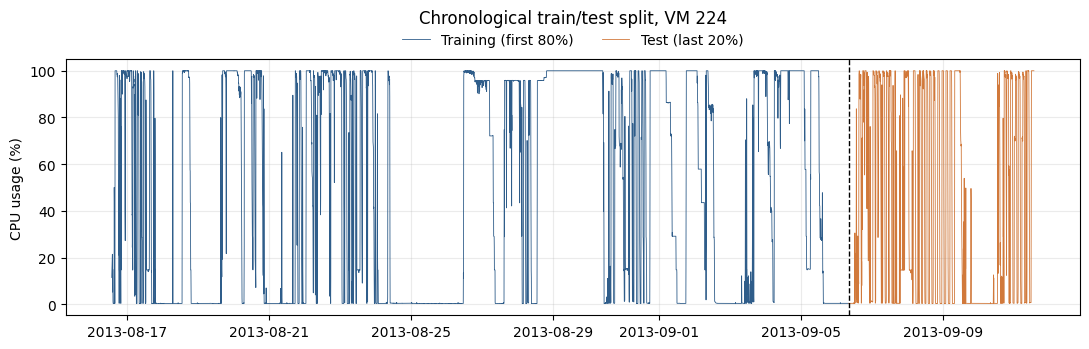

Saved chart: phase2_example_split.png (VM 224)


In [ ]:
# Pick the VM whose CPU varies the most, so the chart actually shows something
example_vm = feat_main.groupby('vm_id')['cpu_usage_pct'].std().idxmax()
ex = feat_main[feat_main['vm_id'] == example_vm]
cut = ex.loc[ex['split'] == 'test', 'timestamp'].min()

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(ex.loc[ex.split == 'train', 'timestamp'], ex.loc[ex.split == 'train', 'cpu_usage_pct'],
        lw=0.6, color='#2f5d8a', label='Training (first 80%)')
ax.plot(ex.loc[ex.split == 'test', 'timestamp'], ex.loc[ex.split == 'test', 'cpu_usage_pct'],
        lw=0.6, color='#d1793b', label='Test (last 20%)')
ax.axvline(cut, color='black', ls='--', lw=1)
ax.set_title(f'Chronological train/test split, VM {example_vm}', pad=26)
ax.set_ylabel('CPU usage (%)')
ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=2, frameon=False)
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(C.CHARTS_DIR / 'phase2_example_split.png', dpi=C.CHART_DPI)
plt.show()
log.info(f'Saved chart: phase2_example_split.png (VM {example_vm})')

## 5. Save everything

In [ ]:
feat_main.to_parquet(C.DATA_PROCESSED / 'features_main.parquet', index=False)
train.to_parquet(C.DATA_PROCESSED / 'train.parquet', index=False)
test.to_parquet(C.DATA_PROCESSED / 'test.parquet', index=False)
feat_gen.to_parquet(C.DATA_PROCESSED / 'features_generalization.parquet', index=False)
with open(C.DATA_PROCESSED / 'feature_columns.json', 'w') as f:
    json.dump({'features': U.FEATURE_COLUMNS, 'target': C.TARGET,
               'n_train_vms': C.N_TRAIN_VMS, 'n_gen_vms': C.N_GEN_VMS}, f, indent=2)

for name in ['features_main.parquet', 'train.parquet', 'test.parquet',
             'features_generalization.parquet', 'feature_columns.json']:
    size = (C.DATA_PROCESSED / name).stat().st_size / 1e6
    log.info(f'Saved: data/processed/{name} ({size:.1f} MB)')
log.info('PHASE 2 COMPLETE')

Saved: data/processed/features_main.parquet (14.4 MB)
Saved: data/processed/train.parquet (11.6 MB)
Saved: data/processed/test.parquet (3.1 MB)
Saved: data/processed/features_generalization.parquet (27.9 MB)
Saved: data/processed/feature_columns.json (0.0 MB)
PHASE 2 COMPLETE


## Done: what to check

- The **leakage checks** table: every row should say `True`. The notebook stops with an error if one doesn't.
- The **split summary**: 50 VMs in both training and test, 100 in generalization, roughly an 80/20 row split, and the test period should start after the training period.
- The mean CPU in training vs test: if they're very different, the last week of the month behaved differently. That's worth knowing when we read the Phase 3 results.

Next: `03_model_training.ipynb` trains the six models.